In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

import shap

import random

seed = 42

random.seed(seed)
np.random.seed(seed)

from catboost import CatBoostRegressor

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from hyperopt import (
    fmin,
    tpe,
    hp,
    Trials,
    STATUS_OK
)

In [2]:
data = pd.read_csv("/home/aashr/-/Py/Minor_Spec/Papers/1-s2.0-S2666016424001440-mmc1.csv")
data

,ID,Type of MB,Types of contaminants,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,1,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,2,polypropylene (PP),Caprolactam,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,3,polypropylene (PP),Creatine,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,4,polypropylene (PP),Formaldehyde,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,5,polypropylene (PP),Isopropanol,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,1903,Poly(p-phenylene oxide) (PPO),Indomethacin,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,1904,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,1905,Poly(p-phenylene oxide) (PPO),Diltiazem,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,1906,Poly(p-phenylene oxide) (PPO),Erythromycin,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [3]:
# data = data[[
#     "Compound Mw (g/mol)",
#     "Compound Kow",
#     "Pressure (kPa)",
#     "Measurement time (min)",
#     "Initial concentration of compound (mg/L)",
#     "min projection (Å)",
#     "max projection (Å)",
#     "MB MWCO (Da)",
#     "MB contact angle (°)",
#     "MB zeta potential",
#     "Compound charge",
#     "pH",
#     "removal rate (%)"
# ]].copy()

# data = data.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
# data

In [4]:

# df = pd.get_dummies(data, columns=["Type of MB"])
# df = pd.get_dummies(df, columns=[ "Types of contaminants"])
# df = df.drop(columns=["ID"])

df = data.copy()
features_6 = [
 "MB MWCO (Da)",
 "Compound Mw (g/mol)",
 "Type of MB",
 "Types of contaminants",
 "Measurement time (min)",
 "max projection (Å)"                     
]

In [5]:
# df = df.dropna()

In [6]:
len(df.columns)

18

In [7]:
# Paper-style 6-feature setup: keep the same exact variables used in the study
# and avoid any invalid log transform on negative Kow values.
Y =pd.to_numeric(
    data["removal rate (%)"],
    errors="coerce"
).astype(float)
X = df[features_6].copy()

# Convert all features to numeric and keep only valid rows
categorical_features = [
    "Types of contaminants",
    "Type of MB"
]


print("X shape:", X.shape)
print("Categorical features:", categorical_features)
print(X.head())

X shape: (1906, 6)
Categorical features: ['Types of contaminants', 'Type of MB']
   MB MWCO (Da)  Compound Mw (g/mol)          Type of MB  \
0           150              162.229  polypropylene (PP)   
1           150              113.160  polypropylene (PP)   
2           150              131.135  polypropylene (PP)   
3           150               30.026  polypropylene (PP)   
4           150               60.096  polypropylene (PP)   

       Types of contaminants  Measurement time (min)  max projection (Å)  
0  2-(2-Butoxyethoxy)ethanol                    10.0                8.08  
1                Caprolactam                    10.0                4.01  
2                   Creatine                    10.0                4.36  
3               Formaldehyde                    10.0                2.34  
4                Isopropanol                    10.0                3.36  


In [8]:
for col in categorical_features:

    X[col] = (
        X[col]
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

for col in categorical_features:
    print(f"\n{col}")
    print("Unique categories:", X[col].nunique())
    print(X[col].value_counts().head(10))


Types of contaminants
Unique categories: 230
Types of contaminants
Ibuprofen                   71
Hydrocortisone              61
perﬂuorohexanoate           59
Sulfamethoxazole            56
Bromoform                   50
Dexamethasone               48
perﬂuorooctane sulfonate    44
Procaine                    42
Carbamazepine               42
Lidocaine                   42
Name: count, dtype: int64

Type of MB
Unique categories: 21
Type of MB
polyvinylidene fluoride (PVDF)      366
Polyallylamine (PAA)                311
polysulfone (PSf)                   255
Polyimide (PI)                      211
polyethylene (PE)                   166
polytetrafluoroethylene (PTFE)       97
Poly(methyl methacrylate) (PMMA)     80
polypropylene (PP)                   76
Polyamidoamine (PAMAM)               76
Polyvinyl alcohol (PVA)              54
Name: count, dtype: int64


In [9]:
numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

for col in numeric_features:
    X[col] = pd.to_numeric(X[col],errors="coerce")

X[numeric_features] = X[numeric_features].replace([np.inf, -np.inf],np.nan)

In [10]:
# Keep the raw Compound Kow values. The paper dataset contains negative Kow values,
# so log10 would produce invalid values and distort the model.
print("Final X shape:", X.shape)

Final X shape: (1906, 6)


In [11]:
X

,MB MWCO (Da),Compound Mw (g/mol),Type of MB,Types of contaminants,Measurement time (min),max projection (Å)
0,150,162.229,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,10.0,8.08
1,150,113.160,polypropylene (PP),Caprolactam,10.0,4.01
2,150,131.135,polypropylene (PP),Creatine,10.0,4.36
3,150,30.026,polypropylene (PP),Formaldehyde,10.0,2.34
4,150,60.096,polypropylene (PP),Isopropanol,10.0,3.36
...,...,...,...,...,...,...
1901,200,357.790,Poly(p-phenylene oxide) (PPO),Indomethacin,1440.0,8.54
1902,200,347.390,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,1440.0,6.38
1903,200,414.520,Poly(p-phenylene oxide) (PPO),Diltiazem,1440.0,8.50
1904,200,733.937,Poly(p-phenylene oxide) (PPO),Erythromycin,1440.0,9.32


In [12]:
# view = data.drop(columns=["Type of MB", "Types of contaminants"])
print(df.min())
print(df.max())


ID                                                                          1
Type of MB                                   Poly(methyl methacrylate) (PMMA)
Types of contaminants                                          1,2-ethanediol
pH                                                                        2.2
Compound Mw (g/mol)                                                    30.026
Compound charge                                                          -2.0
Compound Kow                                                             -6.3
min projection (Å)                                                       2.08
max projection (Å)                                                       2.34
MB MWCO (Da)                                                               65
MB contact angle (°)                                                     14.4
MB zeta potential                                                        -1.0
Total charge                                                    

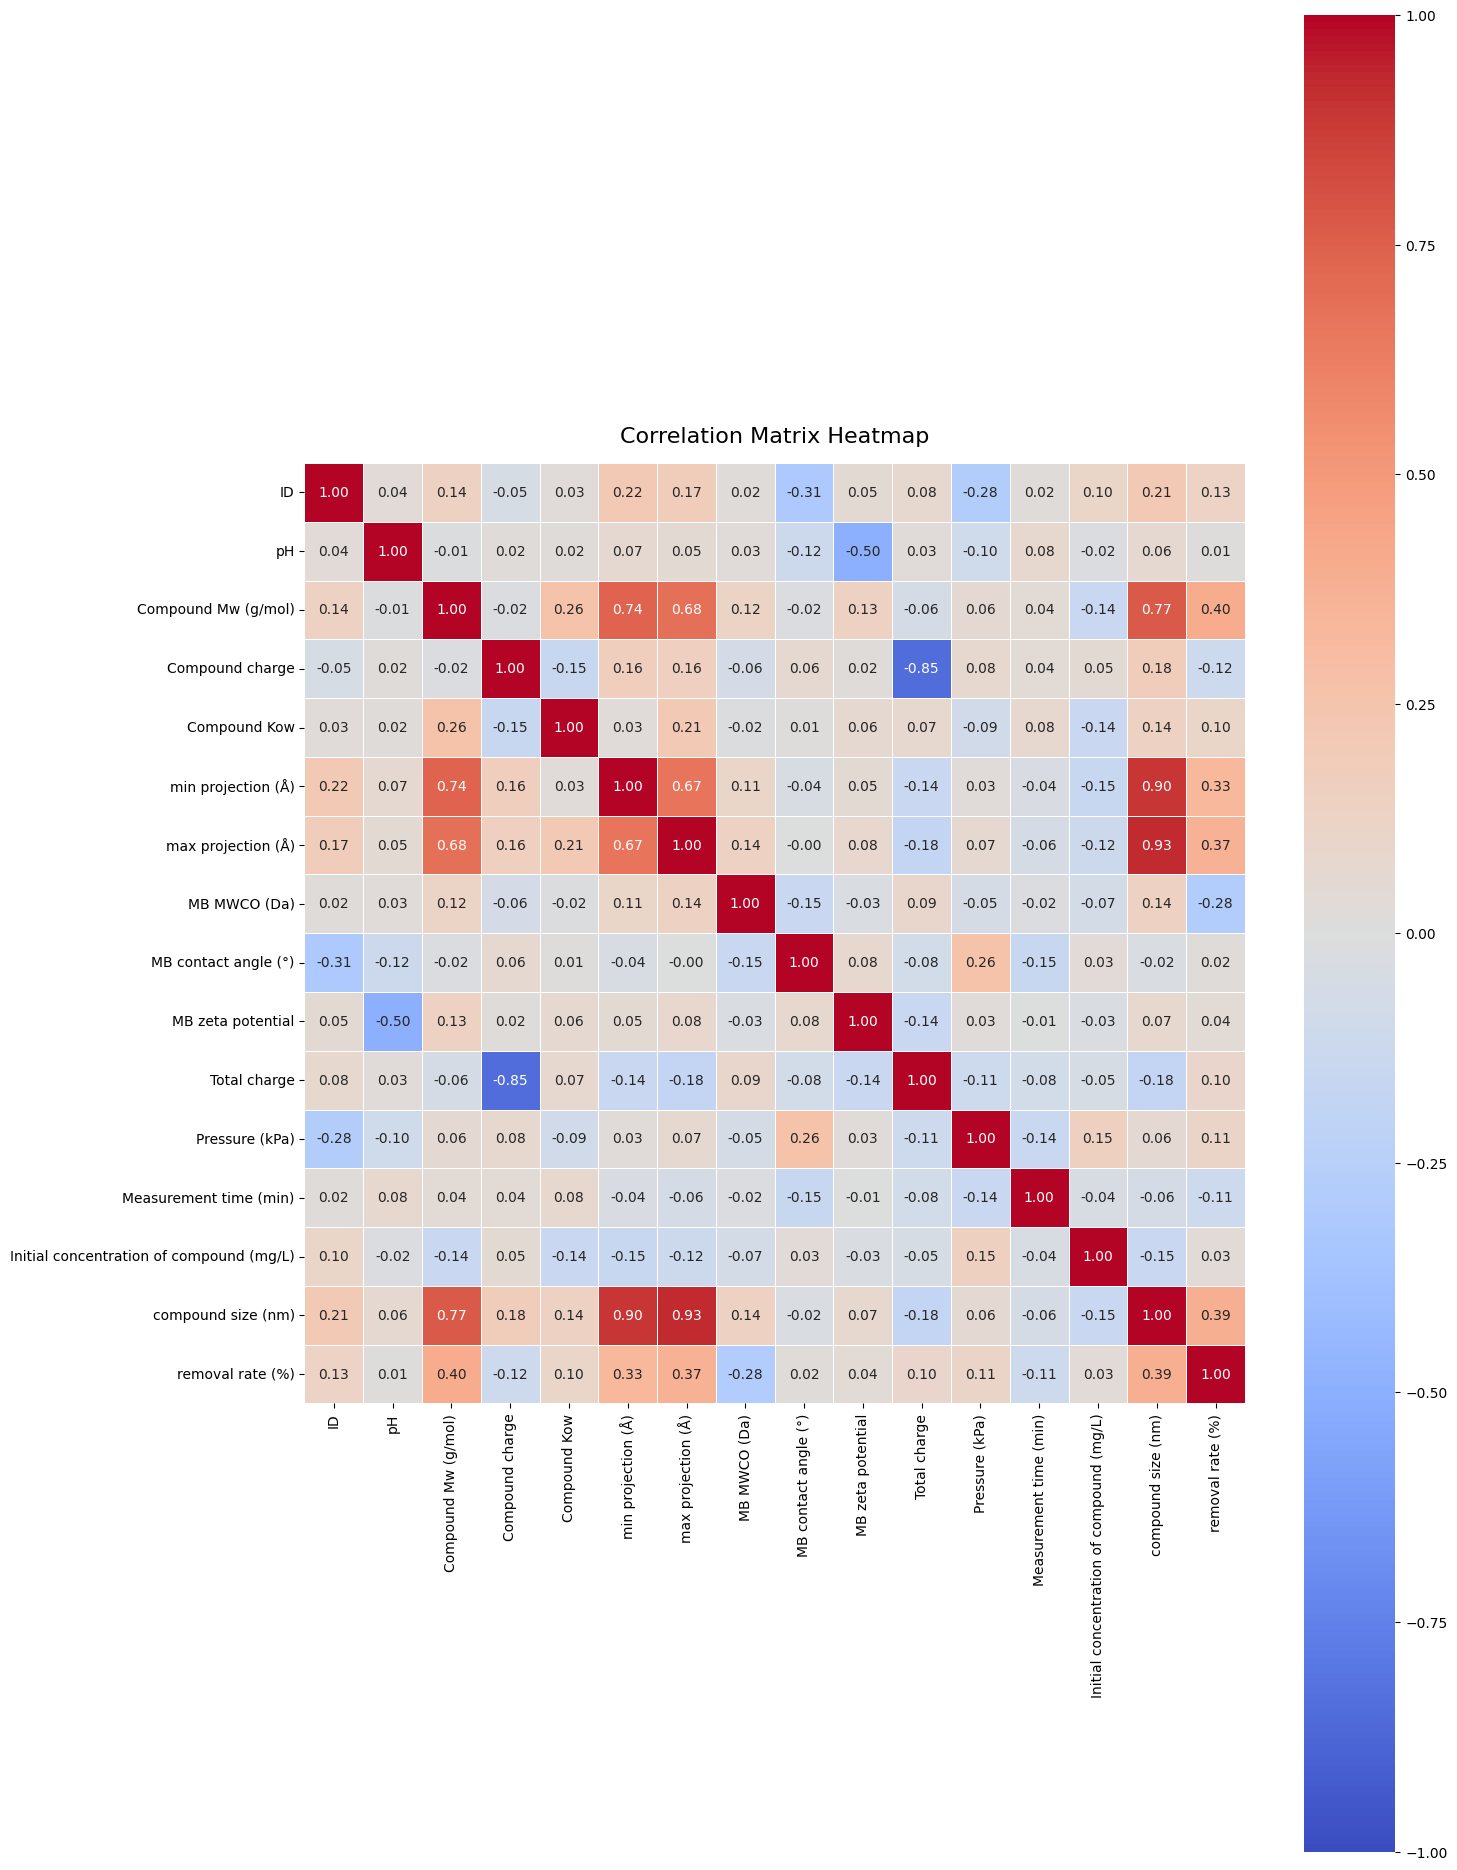

In [13]:
df_num = df.select_dtypes(include=[np.number])
corr = df_num.corr()
# 3. Create a clean heatmap
plt.figure(figsize=(15, 19))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Matrix Heatmap", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

In [14]:
# from scipy import stats
# import numpy as np

# z = np.abs(stats.zscore(X))
# mask = (z < 3).all(axis=1)

# X = X[mask]
# Y = Y[mask]
# X

In [15]:
valid_mask = (
    X[numeric_features]
    .notna()
    .all(axis=1)
    &
    Y.notna()
)
X = X.loc[valid_mask]
Y = Y.loc[valid_mask]

In [16]:
print(X.shape)
X

(1906, 6)


,MB MWCO (Da),Compound Mw (g/mol),Type of MB,Types of contaminants,Measurement time (min),max projection (Å)
0,150,162.229,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,10.0,8.08
1,150,113.160,polypropylene (PP),Caprolactam,10.0,4.01
2,150,131.135,polypropylene (PP),Creatine,10.0,4.36
3,150,30.026,polypropylene (PP),Formaldehyde,10.0,2.34
4,150,60.096,polypropylene (PP),Isopropanol,10.0,3.36
...,...,...,...,...,...,...
1901,200,357.790,Poly(p-phenylene oxide) (PPO),Indomethacin,1440.0,8.54
1902,200,347.390,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,1440.0,6.38
1903,200,414.520,Poly(p-phenylene oxide) (PPO),Diltiazem,1440.0,8.50
1904,200,733.937,Poly(p-phenylene oxide) (PPO),Erythromycin,1440.0,9.32


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape) 


Train shape: (1524, 6)
Test shape: (382, 6)


In [18]:
cat_features = [
    "Types of contaminants",
    "Type of MB"
]

print("Categorical features:", cat_features)

Categorical features: ['Types of contaminants', 'Type of MB']


In [19]:
param_space = {
    "iterations": hp.quniform("cat_iterations", 100, 600, 50),
    "depth": hp.quniform("cat_depth", 4, 8, 1),
    "learning_rate": hp.loguniform(
        "cat_learning_rate",
        np.log(0.01),
        np.log(0.2)
    ),
    "l2_leaf_reg": hp.loguniform(
        "cat_l2_leaf_reg",
        np.log(1),
        np.log(20)
    ),
    "random_strength": hp.uniform(
        "cat_random_strength",
        0,
        2
    ),
    "bagging_temperature": hp.uniform(
        "cat_bagging_temperature",
        0,
        2
    )
}


def objective(params):
    params["iterations"] = int(params["iterations"])
    params["depth"] = int(params["depth"])

    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = []

    for train_idx, val_idx in kf.split(X_train):
        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = CatBoostRegressor(
            loss_function="RMSE",
            bootstrap_type="Bayesian",
            random_seed=42,
            verbose=False,
            cat_features=cat_features,
            task_type="GPU",
            devices="0",
            **params
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
        scores.append(r2_score(y_val, pred))

    mean_r2 = np.mean(scores)

    return {
        "loss": -mean_r2,
        "status": STATUS_OK
    }

In [20]:
print("Starting CatBoost Hyperopt optimization...")

trials = Trials()

best_params = fmin(
    fn=objective,
    space=param_space,
    algo=tpe.suggest,
    max_evals=50,
    trials=trials,
    rstate=np.random.default_rng(42)
)

print("\n--- Optimization Complete ---")

Starting CatBoost Hyperopt optimization...
100%|██████████| 50/50 [29:46<00:00, 35.72s/trial, best loss: -0.6198417643970053]

--- Optimization Complete ---


In [22]:
best_params = {
    "iterations": int(best_params["cat_iterations"]),
    "depth": int(best_params["cat_depth"]),
    "learning_rate": best_params["cat_learning_rate"],
    "l2_leaf_reg": best_params["cat_l2_leaf_reg"],
    "random_strength": best_params["cat_random_strength"],
    "bagging_temperature": best_params["cat_bagging_temperature"]
}

best_cv_score = -trials.best_trial["result"]["loss"]
print("Best Parameters:")
print(best_params)

print(
    f"Best CV R² Score: "
    f"{best_cv_score:.4f}"
)

Best Parameters:
{'iterations': 400, 'depth': 6, 'learning_rate': np.float64(0.08881473542841273), 'l2_leaf_reg': np.float64(8.198213608451038), 'random_strength': np.float64(0.2758231190046093), 'bagging_temperature': np.float64(0.4038841009306375)}
Best CV R² Score: 0.6198


In [23]:
final_cat_model_cat = CatBoostRegressor(
    loss_function="RMSE",
    bootstrap_type="Bayesian",
    random_seed=42,
    task_type="GPU",
    cat_features=cat_features,
    devices="0",
    verbose=False,
    **best_params
)

final_cat_model_cat.fit(
    X_train,
    y_train
)

CatBoostRegressor(bagging_temperature=np.float64(0.4038841009306375), bootstrap_type='Bayesian', cat_features=['Types of contaminants', 'Type of MB'], depth=6, devices='0', iterations=400, l2_leaf_reg=np.float64(8.198213608451038), learning_rate=np.float64(0.08881473542841273), loss_function='RMSE', random_seed=42, random_strength=np.float64(0.2758231190046093), task_type='GPU', verbose=False)

In [24]:
cat_pred = final_cat_model_cat.predict(
    X_test
)

cat_mse = mean_squared_error(
    y_test,
    cat_pred
)

cat_rmse = np.sqrt(cat_mse)

cat_mae = mean_absolute_error(
    y_test,
    cat_pred
)

cat_r2 = r2_score(
    y_test,
    cat_pred
)

print("\n--- CatBoost Final Test Set Metrics ---")

print(f"MSE: {cat_mse:.4f}")
print(f"RMSE: {cat_rmse:.4f}")
print(f"MAE: {cat_mae:.4f}")
print(f"R² Score: {cat_r2:.4f}")


--- CatBoost Final Test Set Metrics ---
MSE: 271.5698
RMSE: 16.4794
MAE: 11.2861
R² Score: 0.6443


/tmp/ipykernel_42946/484676092.py:19: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


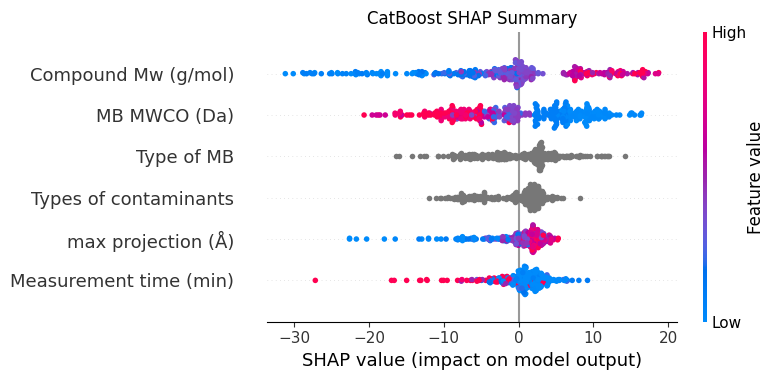


--- Top 6 Most Important Features ---
                  feature  importance
1     Compound Mw (g/mol)    7.603369
0            MB MWCO (Da)    6.739833
2              Type of MB    4.150383
3   Types of contaminants    3.131659
5      max projection (Å)    2.721783
4  Measurement time (min)    2.475478


In [25]:
from catboost import Pool

feature_names = X_test.columns.tolist()

test_pool = Pool(
    data=X_test,
    cat_features=cat_features
)

cat_shap_values = final_cat_model_cat.get_feature_importance(
    test_pool,
    type="ShapValues"
)

# Last column contains the expected value, not a feature
cat_shap_values = cat_shap_values[:, :-1]

plt.figure(figsize=(10, 7))
shap.summary_plot(
    cat_shap_values,
    X_test,
    feature_names=feature_names,
    show=False
)
plt.title("CatBoost SHAP Summary")
plt.tight_layout()
plt.show()

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": np.abs(cat_shap_values).mean(axis=0)
}).sort_values("importance", ascending=False)

top6 = feature_importance.head(6)
print("\n--- Top 6 Most Important Features ---")
print(top6)